# Whiff Prediction

## Imports and Data Preparation

In [1]:
import pandas as pd
from pathlib import Path

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
csv_path = Path("mlb_pitches_2026.csv")
if not csv_path.exists():
    csv_path = Path("mlb_pitches_2026.csv")

pitches = pd.read_csv(csv_path)
pitches.shape

(716792, 119)

## Feature Selection

### Creating `is_whiff` Column

In [3]:
contact_events = {
    "foul",
    "foul_tip",
    "foul_bunt",
    "bunt_foul_tip",
    "hit_into_play",
}
whiff_events = {
    "swinging_strike",
    "swinging_strike_blocked",
    "missed_bunt",
    "swinging_pitchout",
}
pitches["is_swing"] = pitches["description"].isin(contact_events | whiff_events)
pitches["is_whiff"] = pitches["description"].isin(whiff_events)
pitches[["description", "is_swing", "is_whiff"]].head(5)

,description,is_swing,is_whiff
0,swinging_strike,True,True
1,swinging_strike,True,True
2,called_strike,False,False
3,hit_into_play,True,False
4,hit_into_play,True,False


## Exploratory Data Analysis

To match our baseline model, this section uses all pitches, labeling each as a whiff or non-whiff. A whiff rate is the number of swinging strikes divided by the number of pitches. We examine how whiff rate changes with pitch type, release speed, pitch location, and the ball–strike count to guide feature selection.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

eda = pitches.copy()
eda["is_whiff"] = eda["is_whiff"].astype(int)
print(f"Pitches: {len(eda):,}; overall whiff rate: {eda['is_whiff'].mean():.3f}")

Pitches: 716,792; overall whiff rate: 0.109


### Whiff Rate by Pitch Type

Pitch types with fewer than 1,000 pitches are excluded so rates are not driven by small samples. The red dashed line marks the overall whiff rate.

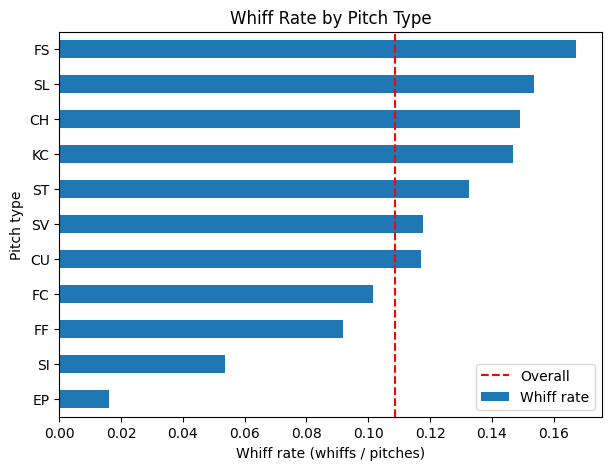

In [5]:
by_type = (eda.groupby("pitch_type")["is_whiff"]
           .agg(whiff_rate="mean", n="size")
           .query("n >= 1000")
           .sort_values("whiff_rate"))

ax = by_type["whiff_rate"].plot(kind="barh", figsize=(7, 5), label="Whiff rate")
ax.axvline(eda["is_whiff"].mean(), color="red", linestyle="--", label="Overall")
ax.set_xlabel("Whiff rate (whiffs / pitches)")
ax.set_ylabel("Pitch type")
ax.set_title("Whiff Rate by Pitch Type")
ax.legend()
plt.show()

### Whiff Rate vs. Release Speed

Speed is plotted separately for the five most common pitch types because pitch types differ systematically in speed; pooling them could hide or reverse the relationship within each type. Speed bins with fewer than 200 pitches are omitted.

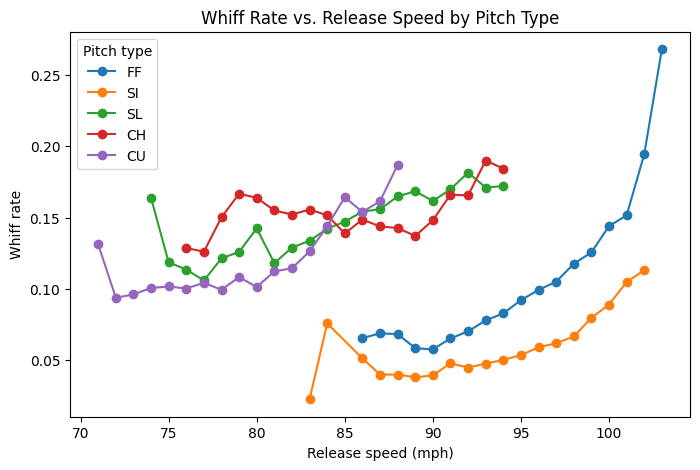

In [6]:
main_types = ["FF", "SI", "SL", "CH", "CU"]
subset = eda[eda["pitch_type"].isin(main_types)].copy()
subset["speed_bin"] = subset["release_speed"].round()

fig, ax = plt.subplots(figsize=(8, 5))
for pitch in main_types:
    rates = subset[subset["pitch_type"] == pitch].groupby("speed_bin")["is_whiff"].agg(["mean", "size"])
    rates = rates[rates["size"] >= 200]
    ax.plot(rates.index, rates["mean"], marker="o", label=pitch)
ax.set_xlabel("Release speed (mph)")
ax.set_ylabel("Whiff rate")
ax.set_title("Whiff Rate vs. Release Speed by Pitch Type")
ax.legend(title="Pitch type")
plt.show()

### Whiff Rate by Pitch Location

Each square shows the whiff rate for pitches at that plate location, from the catcher's view. Squares with fewer than 50 pitches are left blank. The black rectangle is an approximate strike zone.

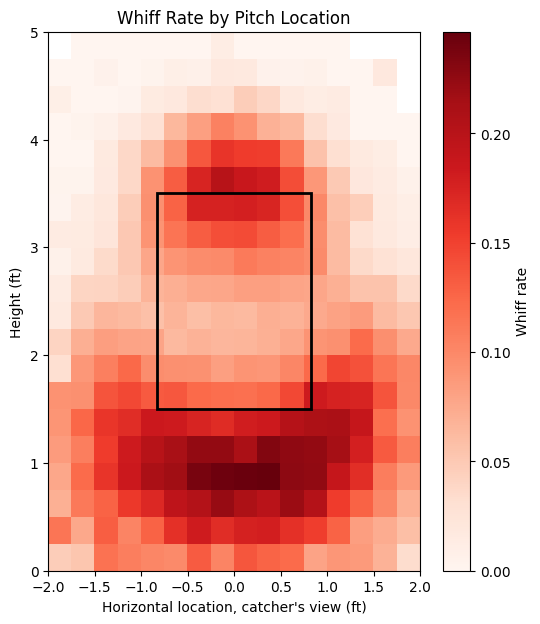

In [7]:
loc = eda.dropna(subset=["plate_x", "plate_z"]).copy()
loc["x_bin"] = pd.cut(loc["plate_x"], bins=np.arange(-2, 2.01, 0.25))
loc["z_bin"] = pd.cut(loc["plate_z"], bins=np.arange(0, 5.01, 0.25))

grid = loc.pivot_table(index="z_bin", columns="x_bin", values="is_whiff",
                       aggfunc="mean", observed=False)
counts = loc.pivot_table(index="z_bin", columns="x_bin", values="is_whiff",
                         aggfunc="size", observed=False)
grid = grid.where(counts >= 50)

fig, ax = plt.subplots(figsize=(6, 7))
im = ax.imshow(grid, origin="lower", extent=[-2, 2, 0, 5], cmap="Reds", aspect="auto")
ax.add_patch(plt.Rectangle((-0.83, 1.5), 1.66, 2.0, fill=False, color="black", lw=2))
fig.colorbar(im, label="Whiff rate")
ax.set_xlabel("Horizontal location, catcher's view (ft)")
ax.set_ylabel("Height (ft)")
ax.set_title("Whiff Rate by Pitch Location")
plt.show()

### Whiff Rate by Ball–Strike Count

Each cell shows the whiff rate for pitches thrown in that count.

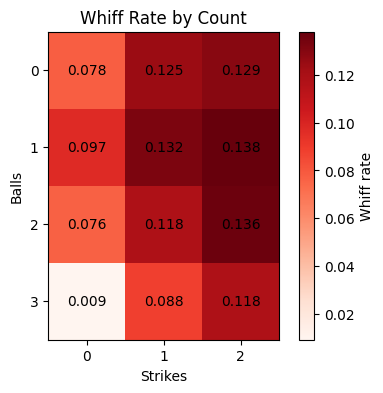

In [8]:
count_grid = eda[eda["balls"] <= 3].pivot_table(
    index="balls", columns="strikes", values="is_whiff", aggfunc="mean")

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(count_grid, cmap="Reds")
for i in range(count_grid.shape[0]):
    for j in range(count_grid.shape[1]):
        ax.text(j, i, f"{count_grid.iloc[i, j]:.3f}", ha="center", va="center")
ax.set_xticks(range(count_grid.shape[1]), count_grid.columns)
ax.set_yticks(range(count_grid.shape[0]), count_grid.index)
ax.set_xlabel("Strikes")
ax.set_ylabel("Balls")
ax.set_title("Whiff Rate by Count")
fig.colorbar(im, label="Whiff rate")
plt.show()

### EDA Takeaways

- **Pitch type:** Whiff rates differ sharply by pitch type. Splitters (FS, about 0.17), sliders (SL), changeups (CH), and knuckle curves (KC) (about 0.15 each) are well above the overall rate of 0.109, while four-seam fastballs (FF, about 0.09) and sinkers (SI, about 0.05) are below it. Breaking and offspeed pitches generally produce more whiffs than fastballs.
- **Speed:** Whiff rate rises with velocity within every main pitch type. The effect is strongest for four-seamers, which go from about 0.07 below 90 mph to about 0.27 at 103 mph. Sinkers rise from about 0.04 to about 0.11. Because the size of the speed effect depends on pitch type, a speed × pitch type interaction may be useful.
- **Location:** Whiffs concentrate just below the strike zone (about 0.5–1.5 ft high) and near the top of the zone. Pitches far outside the zone have whiff rates near zero, likely because batters rarely swing at them, while pitches in the middle of the zone are often hit. Because whiff rate per pitch combines whether the batter swings and whether they miss, location matters in a nonlinear way. `plate_x` and `plate_z` are not in the current model and are strong candidates to add.
- **Count:** Whiff rate rises with strikes, from about 0.08–0.10 with 0 strikes to about 0.12–0.13 with 2 strikes. It is near zero in 3–0 counts (0.009), when batters usually take the pitch. Counts affect whiff rate in a nonlinear way, so treating the count as a category may work better than separate numeric balls and strikes.

These patterns support keeping pitch type, speed, and count, and motivate adding plate location as a predictor.

### Selecting Relevant Features

Use pitch characteristics, pitch type, count, inning context, batter, and pitcher as predictors. Exclude `description` and `is_swing` because they are derived from the event used to create `is_whiff`; retaining them would leak the answer into the features. Keep `is_whiff` as the target.

In [9]:
pitches = pitches.drop(columns=["description", "is_swing"], errors="ignore")
feature_columns = [
    "pitch_type",
    "release_speed",
    "release_pos_x",
    "release_pos_z",
    "zone",
    "stand",
    "p_throws",
    "balls",
    "strikes",
    "outs_when_up",
    "inning",
    "inning_topbot",
    "pitcher",
    "batter",
]
category_columns = ["pitch_type", "stand", "p_throws", "inning_topbot", "pitcher", "batter"]
numeric_columns = [column for column in feature_columns if column not in category_columns]

X = pitches[feature_columns]
y = pitches["is_whiff"].astype(int)

## Model Pipeline

### Train-Test Split and Column Transformations

Use a stratified 70/30 split so the whiff proportion is similar in training and testing data. Impute missing numeric values with the training-set median and missing categorical values with the training-set mode rather than dropping rows; this retains pitches with partially missing predictors. Standardize numeric features and one-hot encode categorical features. Fit both models within pipelines so transformations are learned only from training data.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            numeric_columns,
        ),
        (
            "categorical",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            category_columns,
        ),
    ]
)

print(f"Train rows: {len(X_train):,}; test rows: {len(X_test):,}")

Train rows: 501,754; test rows: 215,038


## Logistic Regression

In [11]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classification", LogisticRegression(class_weight="balanced", max_iter=500)),
    ]
)
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['release_speed',
                                                   'release_pos_x',
                                                   'release_pos_z', 'zone',
                                                   'balls', 'strikes',
                                                   'outs_when_up', 'inning']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('one_hot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['pitch_type', 'stand',
                                                   'p_throws', 'inning_topbot',
                                                   'pitcher', 'batter'])])),
                ('classification',
                 LogisticRegression(class_weight='balanced', max_iter=500))])

In [12]:
logistic_scores = logistic_model.predict_proba(X_test)[:, 1]
logistic_predictions = (logistic_scores >= 0.5).astype(int)
accuracy_score(y_test, logistic_predictions)

0.5984058631497688

## Linear Regression

In [13]:
linear_model = Pipeline(
    steps=[("preprocessor", clone(preprocessor)), ("regression", LinearRegression())]
)
linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['release_speed',
                                                   'release_pos_x',
                                                   'release_pos_z', 'zone',
                                                   'balls', 'strikes',
                                                   'outs_when_up', 'inning']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('one_hot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['pitch_type', 'stand',
                                                   'p_throws', 'inning_topbot',
                                                   'pitcher', 'batter'])])),
                ('regression', LinearRegression())])

In [14]:
linear_scores = linear_model.predict(X_test)
linear_predictions = (linear_scores >= 0.5).astype(int)
accuracy_score(y_test, linear_predictions)

0.8913122331866926

## Comparing Model Results

In [15]:
model_predictions = {
    "Linear regression": (linear_predictions, linear_scores),
    "Logistic regression": (logistic_predictions, logistic_scores),
}
for model_name, (predictions, scores) in model_predictions.items():
    print(f"{model_name}")
    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions))
    print(classification_report(
        y_test,
        predictions,
        target_names=["not whiff", "whiff"],
        zero_division=0,
    ))

Linear regression
Confusion matrix:
[[191665      2]
 [ 23370      1]]
              precision    recall  f1-score   support

   not whiff       0.89      1.00      0.94    191667
       whiff       0.33      0.00      0.00     23371

    accuracy                           0.89    215038
   macro avg       0.61      0.50      0.47    215038
weighted avg       0.83      0.89      0.84    215038

Logistic regression
Confusion matrix:
[[113869  77798]
 [  8560  14811]]
              precision    recall  f1-score   support

   not whiff       0.93      0.59      0.73    191667
       whiff       0.16      0.63      0.26     23371

    accuracy                           0.60    215038
   macro avg       0.55      0.61      0.49    215038
weighted avg       0.85      0.60      0.67    215038



## Model Comparison and Relevant Coefficients

Compare overall accuracy alongside balanced accuracy, precision, recall, F1, ROC AUC, and average precision. The coefficient table shows the 15 largest absolute coefficients per model. Numeric predictors are standardized and categorical predictors are one-hot encoded; coefficient magnitude is most meaningful within each model, not as a direct comparison across models.

In [16]:
comparison = pd.DataFrame(
    {
        name: {
            "Accuracy": accuracy_score(y_test, predictions),
            "Balanced accuracy": balanced_accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions, zero_division=0),
            "Recall": recall_score(y_test, predictions, zero_division=0),
            "F1": f1_score(y_test, predictions, zero_division=0),
            "ROC AUC": roc_auc_score(y_test, scores),
            "Average precision": average_precision_score(y_test, scores),
        }
        for name, (predictions, scores) in model_predictions.items()
    }
).T
display(comparison.round(3))

,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision
Linear regression,0.891,0.500,0.333,0.000,0.000,0.655,0.177
Logistic regression,0.598,0.614,0.160,0.634,0.255,0.656,0.176


## Relevant Coefficients

In [17]:
linear_feature_names = linear_model.named_steps["preprocessor"].get_feature_names_out()
logistic_feature_names = logistic_model.named_steps["preprocessor"].get_feature_names_out()
coefficient_tables = []
for model_name, feature_names, coefficients in [
    (
        "Linear regression",
        linear_feature_names,
        linear_model.named_steps["regression"].coef_,
    ),
    (
        "Logistic regression",
        logistic_feature_names,
        logistic_model.named_steps["classification"].coef_[0],
    ),
]:
    model_coefficients = pd.DataFrame(
        {"Model": model_name, "Feature": feature_names, "Coefficient": coefficients}
    )
    model_coefficients["Absolute coefficient"] = model_coefficients["Coefficient"].abs()
    coefficient_tables.append(model_coefficients.nlargest(15, "Absolute coefficient"))

top_coefficients = pd.concat(coefficient_tables, ignore_index=True)
display(top_coefficients.round(4))

,Model,Feature,Coefficient,Absolute coefficient
0,Linear regression,categorical__batter_687394,0.9913,0.9913
1,Linear regression,categorical__batter_668974,0.6269,0.6269
2,Linear regression,categorical__batter_680577,0.2379,0.2379
3,Linear regression,categorical__pitcher_664059,0.2266,0.2266
4,Linear regression,categorical__batter_665856,0.2023,0.2023
5,Linear regression,categorical__batter_805672,0.1776,0.1776
6,Linear regression,categorical__batter_669087,0.1563,0.1563
7,Linear regression,categorical__pitcher_571771,0.1551,0.1551
8,Linear regression,categorical__pitcher_642585,0.1543,0.1543
9,Linear regression,categorical__batter_657675,0.1438,0.1438


## Model Diagnostics

We compare both models using ROC and precision–recall curves, check which non-ID features drive the logistic model, and check whether predicted probabilities match observed whiff rates.

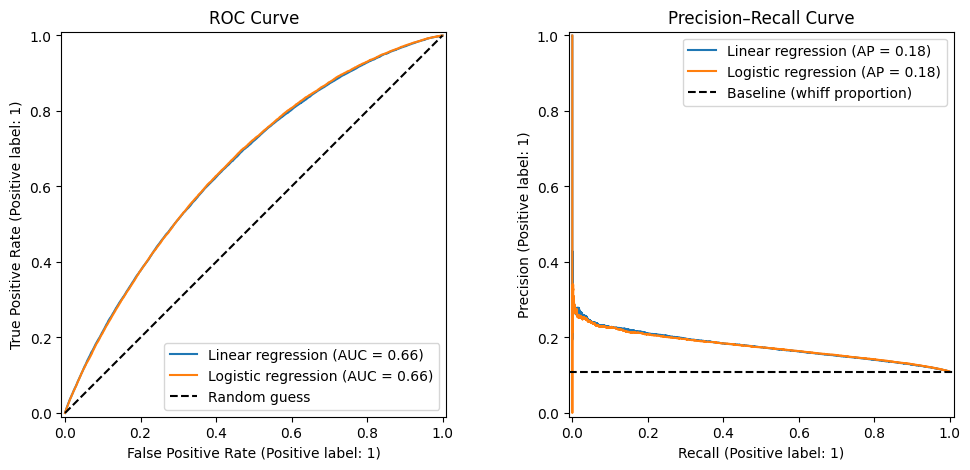

In [18]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, (predictions, scores) in model_predictions.items():
    RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=axes[1])

axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_title("ROC Curve")
axes[0].legend()
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="Baseline (whiff proportion)")
axes[1].set_title("Precision–Recall Curve")
axes[1].legend()
plt.show()

Both models have nearly identical curves (ROC AUC about 0.66; average precision about 0.18 versus a baseline of about 0.11). The models rank whiffs better than chance, but only modestly, so the large accuracy gap earlier comes from the classification threshold, not from better ranking.

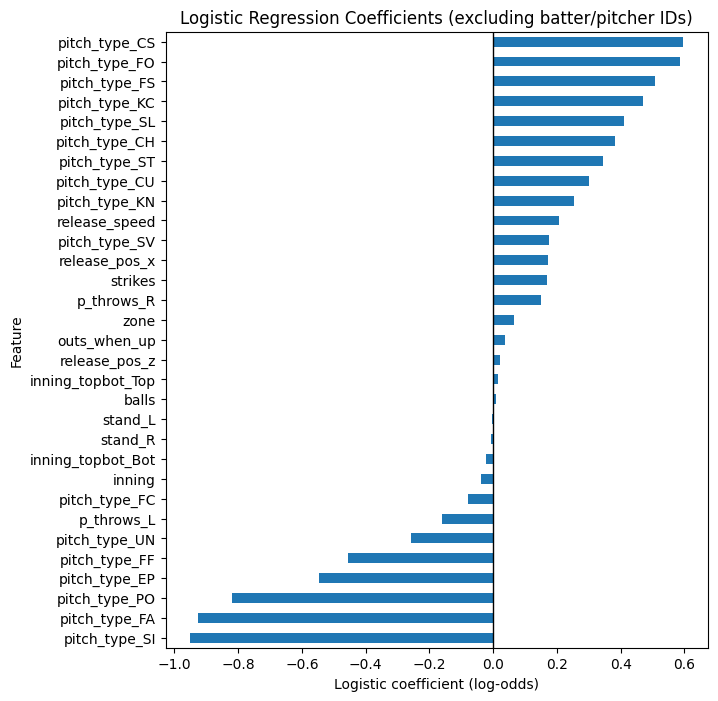

In [19]:
coefficients = pd.DataFrame({
    "Feature": logistic_feature_names,
    "Coefficient": logistic_model.named_steps["classification"].coef_[0],
})
coefficients = coefficients[~coefficients["Feature"].str.contains("batter_|pitcher_")]
coefficients["Feature"] = (coefficients["Feature"]
                           .str.replace("numeric__", "")
                           .str.replace("categorical__", ""))

ax = coefficients.sort_values("Coefficient").plot(
    kind="barh", x="Feature", y="Coefficient", figsize=(7, 8), legend=False)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Logistic coefficient (log-odds)")
ax.set_title("Logistic Regression Coefficients (excluding batter/pitcher IDs)")
plt.show()

The earlier coefficient table was dominated by individual batter and pitcher IDs, which can overfit to players with few pitches. Excluding IDs, the logistic coefficients agree with the EDA: breaking and offspeed pitch types (FS, KC, SL, CH, ST, CU) increase whiff odds, while sinkers (SI) and four-seam fastballs (FF) decrease them. Release speed and strikes also have positive coefficients, consistent with the speed and count plots.

Several of the largest coefficients belong to rare pitch types (CS, FO, PO, EP, FA, UN). These are based on few pitches and should not be over-interpreted. `zone` and `balls` have coefficients near zero even though location and count clearly matter in the EDA. This is likely because they enter the model as single linear terms: `zone` is a label (1–9, 11–14), not a quantity, and the effect of balls is driven mostly by 3–0 counts. Treating `zone` and the count as categories, and adding `plate_x` and `plate_z`, are natural next steps.

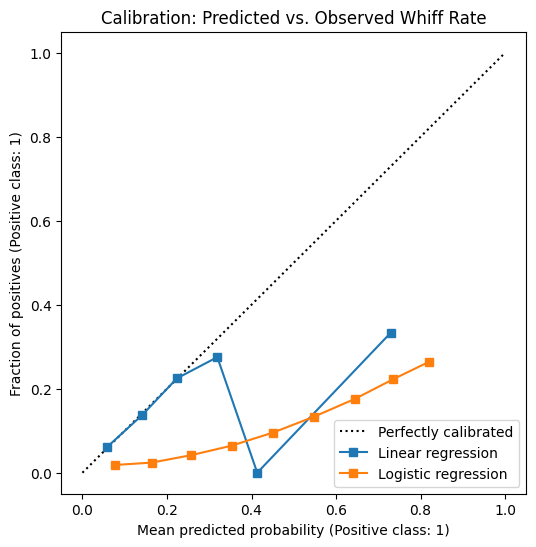

In [20]:
from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(6, 6))
for name, (predictions, scores) in model_predictions.items():
    CalibrationDisplay.from_predictions(y_test, np.clip(scores, 0, 1),
                                        n_bins=10, name=name, ax=ax)
ax.set_title("Calibration: Predicted vs. Observed Whiff Rate")
plt.show()

A well-calibrated model follows the diagonal. Logistic regression falls well below it: for example, pitches given a predicted probability of about 0.8 are whiffs only about 26% of the time. This is expected because `class_weight="balanced"` up-weights whiffs during training, which pushes predicted probabilities upward. Its curve still rises steadily, so it ranks pitches correctly (consistent with its ROC AUC) even though its probabilities should not be read literally.

Linear regression is close to the diagonal for low predictions but erratic above about 0.3, where it makes very few predictions. It almost never predicts above 0.5, which explains why it classifies nearly every pitch as a non-whiff (recall about 0.00) despite its high accuracy. For a model that outputs meaningful whiff probabilities, the next step is logistic regression without class weighting (or with recalibration), combined with a threshold chosen for the goal rather than 0.5.

## Next Steps

- **Data:** Agree as a team on the final dataset (all pitches vs. swings only) and a shared cleaned CSV.
- **Features:** Treat `zone` and the ball–strike count as categorical; add plate location (`plate_x`, `plate_z`) and pitch movement/spin (`pfx_x`, `pfx_z`, `release_spin_rate`).
- **Models:** Refit logistic regression without class weighting or with recalibration, choose a decision threshold suited to our goal, and compare against random forest.
- **Evaluation:** Report ROC AUC, average precision, and log loss, with bootstrap confidence intervals.